# Pagos discretos y descuento por tramos: qué contrato estamos valorando
## Pregunta y continuidad
Después de la integración afín31, el siguiente riesgo es semántico: al convertir un pago en una pendiente suave cambiamos el préstamo. Ahora componemos tramos en fechas de eventos y admitimos fuerzas de descuento distintas. Se conserva la API31 y su integral, no se presenta una fórmula científica inédita.

H técnica fijada en `term_config.json`: error absoluto<1e-6 dinero contra cuadratura midpoint4096 del MISMO contrato por eventos,36regímenes completos. La comparación suave/discreta es sensibilidad a supuestos, no benchmark de superioridad entre métodos para idénticoDGP.

## Formulación y derivación
Sea intervalo $i$ de duración $\Delta_i>0$ años, causas $d_i,p_i\ge0$ y fuerza $r_i\ge0$ año$^{-1}$, EADcondicional afín $E_i(u)$ en dinero y LGD $L\in[0,1]$.

La fórmula31 integraba con fuerza única $r$: $EL_i=S_i e^{-rt_i} Ld_i\int_0^{\Delta_i}E_i(u)e^{-(d_i+p_i+r)u}du$. Su límite era descuento plano y falta de ejemplo explícito de pagos con saltos.

Definimos descuento acumulado $B_i=\exp(-\sum_{j<i}r_j\Delta_j)$ y supervivencia $S_i=\exp[-\sum_{j<i}(d_j+p_j)\Delta_j]$. Al separar la integral anterior del tramo actual:
$$EL=\sum_i S_iB_i\,Ld_i\int_0^{\Delta_i} E_i(u)e^{-(d_i+p_i+r_i)u}du.$$
Cada integral local usa el peso31 $w(x)=1/x-1/(e^x-1)$ con serie estable cerca de0. Recurrencias $B_{i+1}=B_i e^{-r_i\Delta_i}$ y $S_{i+1}=S_i e^{-(d_i+p_i)\Delta_i}$ corresponden directamente a `discount` y `survival` en `src/term_structure.py`. El resultado local ya incorpora densidad de default y descuento relativo; no se aplica descuento dos veces.

Las masas globales son $D=\sum_iS_iD_i^{local}$ y $P=\sum_iS_iP_i^{local}$; $D+P+S_{final}=1$. Todos los factores son adimensionales salvo EAD; ELdinero. No hay identificación/calibración, todos los parámetros se suministran.

In [1]:
from src.term_structure import project_term_structure
from src.term_experiment import quadrature
import json, math, csv
from pathlib import Path
from IPython.display import display, Image
root=Path.cwd()
dt=[.13,.37,.5];d=[.24]*3;p=[1.2]*3;r=[.02,.08,.16];e=[100.,80.,20.]
anchor=project_term_structure(dt,d,p,e,e,r)
print(anchor)
assert abs(anchor.exact_loss-quadrature(dt,d,p,e,r,4096))<1e-6
assert abs(anchor.default_probability+anchor.prepayment_probability+anchor.survival-1)<1e-12
assert abs(anchor.terminal_discount-math.exp(-sum(a*b for a,b in zip(dt,r))))<1e-14

TermResult(exact_loss=3.651612807692989, midpoint_exposure_loss=3.651612807692989, default_probability=0.12717870688631303, prepayment_probability=0.6358935344315653, survival=0.2369277586821218, terminal_discount=0.8938654665285504)


## Pagos: límites y existencia
Un pago programado en $t_i$ reduce la exposición posterior, con $E_{i-1}(\Delta_{i-1})\ne E_i(0)$ permitido. En exposición constante de cada tramo imponemos extremos iguales. No interpolar silenciosamente a través del salto.

Se asumen hazards absolutamente continuos: probabilidad de default exactamente en fecha de pago es cero, así que el valor puntual anterior/posterior no altera la integral. Si hubiera masas atómicas de default en fechas de pago, se necesitaría prioridad contractual explícita y la fórmula actual no aplicaría. Nonnegative finite entradas, vectores1..360; validamos incluso tramos posteriores a supervivencia numéricamente cero. Si $d_i+p_i+r_i=0$, pérdida local cero. Existencia asegurada por horizonte finito, exposición afín acotada y tasas no negativas finitas bajo guardas numéricas.

In [2]:
discrete=project_term_structure([.5,.5],[.24]*2,[1.2]*2,[100.,20.],[100.,20.],[.06]*2)
smooth=project_term_structure([.5,.5],[.24]*2,[1.2]*2,[100.,60.],[60.,20.],[.06]*2)
print('Discrete midyear payment:',discrete.exact_loss)
print('Continuous amortization:',smooth.exact_loss)
print('Difference from contract assumption:',discrete.exact_loss-smooth.exact_loss)
assert abs(discrete.exact_loss-smooth.exact_loss)>.1
assert abs(discrete.exact_loss-discrete.midpoint_exposure_loss)<1e-12

Discrete midyear payment: 4.157861225598016
Continuous amortization: 3.895512384356232
Difference from contract assumption: 0.2623488412417845


## Experimento justo y gráficos
Mismo calendario irregular por eventos; prepago0,.5,1.2,3; desplazamiento paralelo fuerzas0,.05,.2; pagos totales0,40,80:36casos sintéticos. La cuadratura numérica integra constante EAD por evento, no suaviza pagos. Convergencia1..4096paneles por intervalo muestra coste/precisión; no inventa un baseline débil. Medimos7repeticiones25llamadas y picoPython, no RSS ni coste real cloud.

{
  "anchor": {
    "exact_loss": 3.651612807692989,
    "midpoint_exposure_loss": 3.651612807692989,
    "default_probability": 0.12717870688631303,
    "prepayment_probability": 0.6358935344315653,
    "survival": 0.2369277586821218,
    "terminal_discount": 0.8938654665285504
  },
  "discrete_midyear_payment": 4.157861225598016,
  "smooth_same_endpoints": 3.895512384356232,
  "semantic_difference": 0.2623488412417845,
  "cases": 36,
  "max_abs_error": 1.0063933242321355e-08,
  "hypothesis": "max abs error <1e-6 money vs midpoint4096 on same event-DGP",
  "passed": true,
  "timings": {
    "closed_form": {
      "median_seconds": 2.9649360001258174e-05,
      "samples_seconds": [
        3.4293119999802004e-05,
        2.9455439998855583e-05,
        2.982879999990473e-05,
        2.9583240000192745e-05,
        2.8839320000315637e-05,
        3.062400000089838e-05,
        2.9649360001258174e-05
      ],
      "peak_python_bytes": 1432
    },
    "midpoint4096": {
      "median_seco

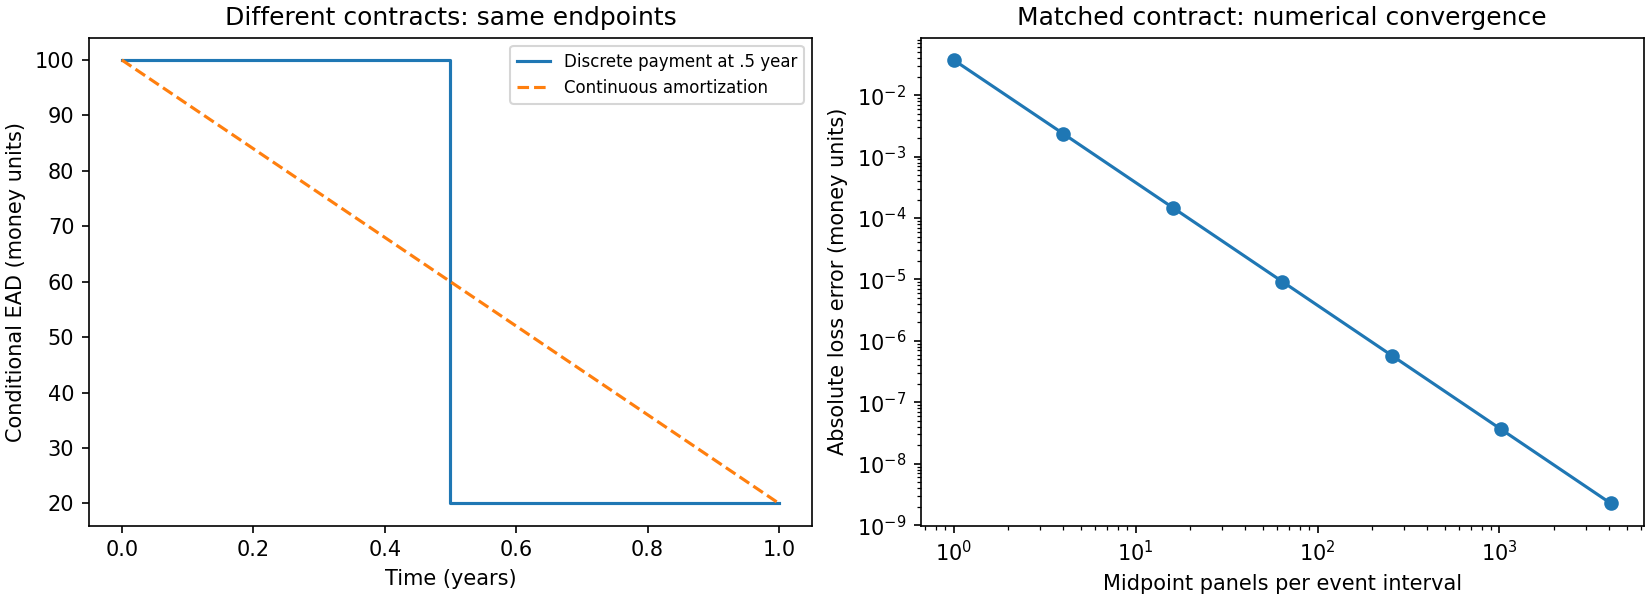

In [3]:
metrics=json.loads((root/'results/term_metrics.json').read_text())
print(json.dumps(metrics,indent=2))
assert metrics['passed']
for row in csv.DictReader((root/'results/term_convergence.csv').open()):print(row)
display(Image(filename=str(root/'results/term.png')))

## Negativos, límites y qué sabemos ahora
Con fuerza plana recuperamos31. Sin pago, las aproximaciones deEADcoinciden; no se fabrica mejora. La comparación discreta/suave tiene distintoDGP, no acredita rendimiento predictivo. Partir un tramo conservando la misma funciónEAD y fuerza no cambia la integral; partirlo con otro pago sí cambia contrato.

Herramienta reutilizable: `project_term_structure`, capaz de valorar calendario de saldos explícito y descuento por tramos antes no documentado. Datos son simulación diseñada: sin censura, EADestocástica, riesgoLGD, estimación ni afirmación regulatoria. Fuentes conocidas de riesgos competidores en matriz `informe1101.md` y5DOI en referencias.bib; no evidencia de originalidad científica. Continuar con fixture de calendario real autorizado; ajustar si hay defaultatómico; no operar sin validación. Ejecución fresh-process secuencialIPython con outputs reales, no kernelaislado.

In [4]:
flat=project_term_structure([1.],[.24],[1.2],[100.],[100.],[0.])
zero=project_term_structure([1.],[0.],[0.],[100.],[100.],[0.])
assert flat.exact_loss==flat.midpoint_exposure_loss
assert zero.exact_loss==0.
print('Negative no exposure slope:',flat)
print((root/'results/tests.txt').read_text())

Negative no exposure slope: TermResult(exact_loss=5.723041809884086, midpoint_exposure_loss=5.723041809884086, default_probability=0.12717870688631303, prepayment_probability=0.6358935344315652, survival=0.23692775868212176, terminal_discount=1.0)
test_constant_reduces_to_original (test_affine.AffineTests.test_constant_reduces_to_original) ... ok
test_decimal_oracle_small_large (test_affine.AffineTests.test_decimal_oracle_small_large) ... ok
test_invalid (test_affine.AffineTests.test_invalid) ... ok
test_negative_direction_and_zero (test_affine.AffineTests.test_negative_direction_and_zero) ... ok
test_partition_invariance_irregular (test_affine.AffineTests.test_partition_invariance_irregular) ... ok
test_properties_multiple_seeds (test_affine.AffineTests.test_properties_multiple_seeds) ... ok
test_closed_form (test_calendar.CalendarTests.test_closed_form) ... ok
test_invalid (test_calendar.CalendarTests.test_invalid) ... ok
test_invalid_bounds (test_calendar.CalendarTests.test_invalid_